### TEL354 - Minería de datos
# Clase 12: Ensembles
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase12 import *

# Árboles de decisión

Representan decisiones y sus posibles consecuencias en forma de árbol. Cada nodo interno del árbol representa una característica o atributo, cada rama representa una decisión basada en esa característica, y cada hoja representa el resultado de una serie de decisiones.

<div align="center">
    <img src="img/tree.png" alt="" width="25%" align="center" />
</div>

# Iris dataset

<div align="center">
    <img src="img/iris.png" alt="" width="70%" align="center" />
</div>

In [2]:
dfIris = sns.load_dataset("iris") 
dfIris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


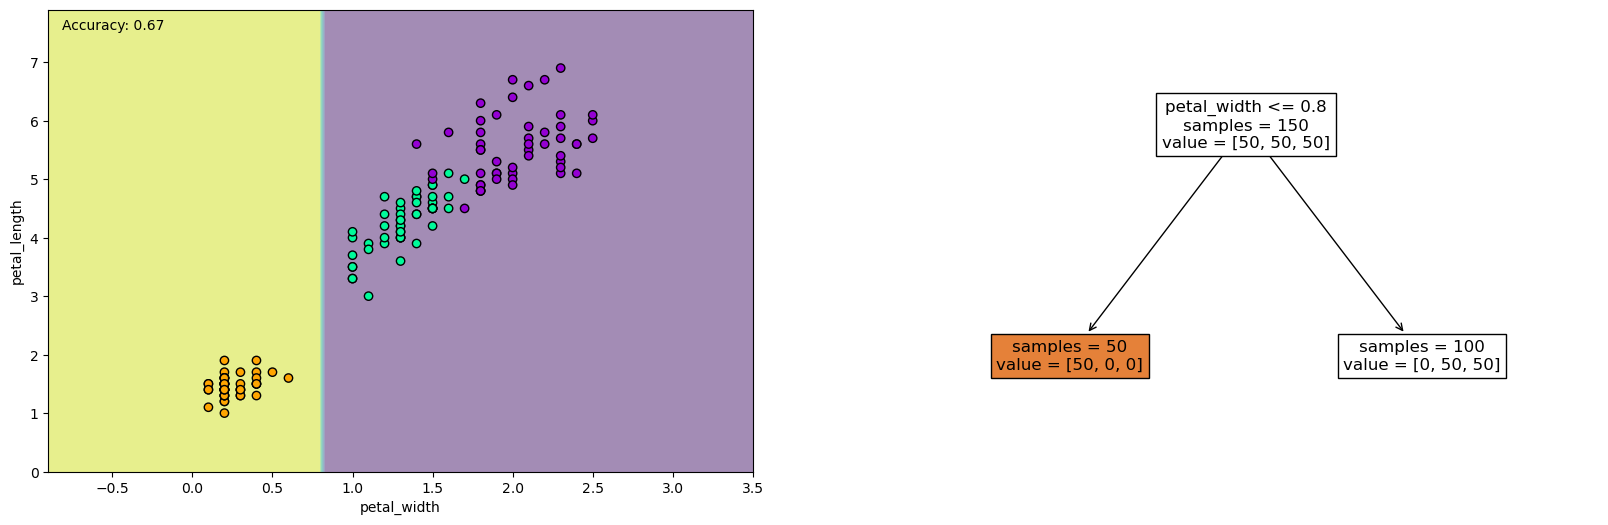

In [3]:
plot_decision_tree(dfIris, depth=1)

# Titanic dataset

In [4]:
df_titanic = pd.read_csv('titanic.csv')

In [5]:
df_titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [6]:
data_titanic = df_titanic.loc[:,('Survived','Pclass','Sex','Age','SibSp','Parch','Fare')]

In [7]:
data_titanic.dropna(inplace=True)

In [8]:
le = LabelEncoder()
data_titanic.Sex = le.fit_transform(data_titanic.Sex)

In [9]:
data_titanic

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,1,22.0,1,0,7.2500
1,1,1,0,38.0,1,0,71.2833
2,1,3,0,26.0,0,0,7.9250
3,1,1,0,35.0,1,0,53.1000
4,0,3,1,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
885,0,3,0,39.0,0,5,29.1250
886,0,2,1,27.0,0,0,13.0000
887,1,1,0,19.0,0,0,30.0000
889,1,1,1,26.0,0,0,30.0000


In [10]:
X_titanic = data_titanic.iloc[:,1:]   
y_titanic = data_titanic.iloc[:,0]   

In [11]:
X_train_titanic, X_test_titanic, y_train_titanic, y_test_titanic = train_test_split(X_titanic, y_titanic, test_size=.3)

In [12]:
dtree_titanic = DecisionTreeClassifier(random_state=42)
dtree_titanic.fit(X_train_titanic, y_train_titanic) 
y_pred_titanic = dtree_titanic.predict(X_test_titanic)

In [13]:
accuracy_score(y_test_titanic, y_pred_titanic)

0.772093023255814

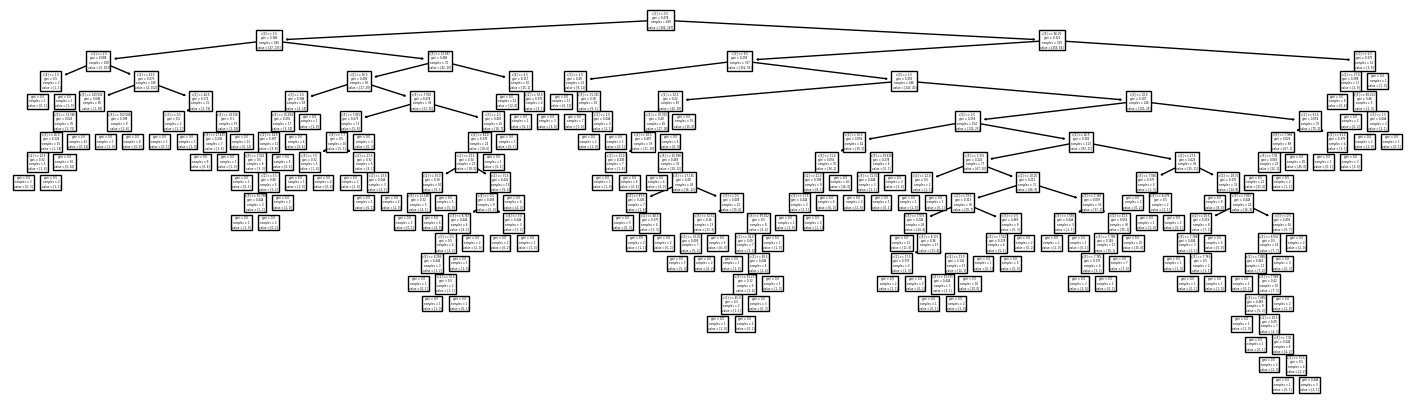

In [14]:
plt.figure(figsize=(18, 5))
tree.plot_tree(dtree_titanic)
plt.show()

# GridSearchCV

Búsqueda exhaustiva sobre valores de parámetros específicos para un estimador. Permite hacer pruebas con diferentes configuraciones para encontrar los parámetros óptimos del modelo.

In [15]:
dtree = DecisionTreeClassifier(random_state=42)

In [16]:
param_grid = {'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 30, 50, 75, 100]}

## Cross-Validation

<div align="right">
    <img src="img/kfold.png" alt="" width="10%" align="right" />
</div>

Para obtener una estimación robusta, independiente de los datos, se utiliza la validación cruzada (cross-validation) que divide el conjunto de datos en varios subconjuntos llamados "folds". Luego, se entrena el modelo con todos los folds menos uno que se usa para evaluar. Este proceso se repite, de modo que cada fold actúa como conjunto de validación exactamente una vez.

In [17]:
# Define a cross-validation splitter with random_state
cv_splitter = KFold(n_splits=5, random_state=42, shuffle=True)

In [18]:
grid_search = GridSearchCV(estimator = dtree, 
                           param_grid = param_grid,
                           cv=cv_splitter).fit(X_train_titanic,y_train_titanic)

In [19]:
grid_search.best_params_

{'max_depth': 5}

In [20]:
dtree_titanic = DecisionTreeClassifier(**grid_search.best_params_)
dtree_titanic.fit(X_train_titanic, y_train_titanic)
y_pred_titanic = dtree_titanic.predict(X_test_titanic)
accuracy_score(y_test_titanic, y_pred_titanic)

0.7767441860465116

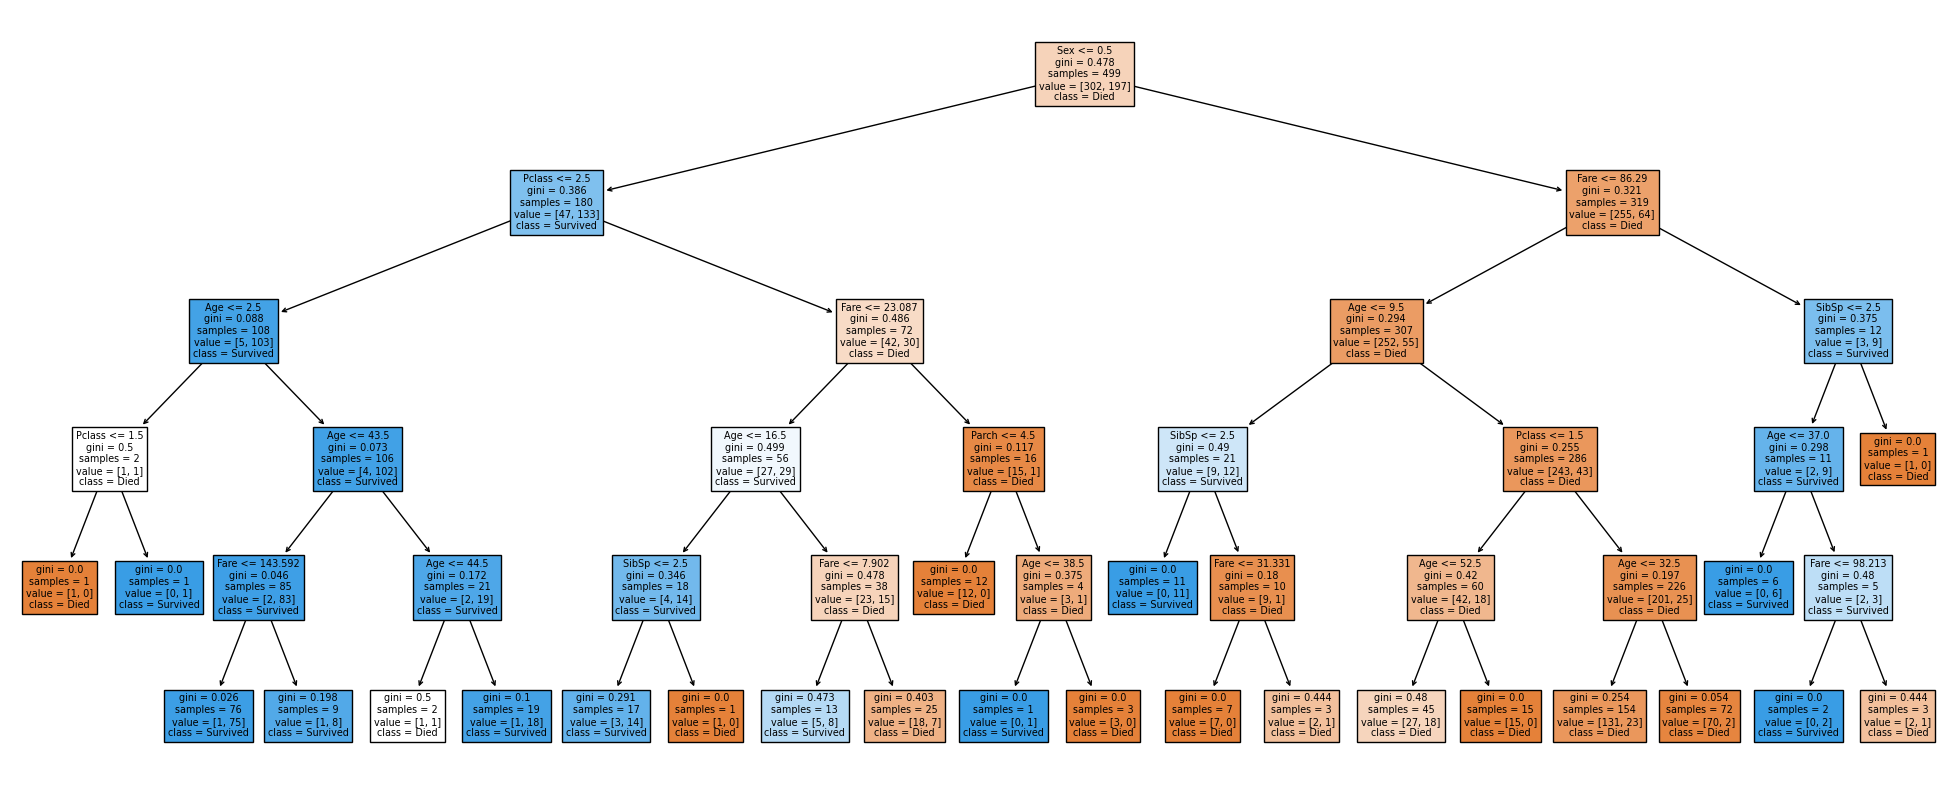

In [21]:
plt.figure(figsize=(25, 10))
tree.plot_tree(dtree_titanic, feature_names = list(data_titanic.iloc[:,1:].columns), 
               class_names = ['Died','Survived'], filled = True)
plt.show()

In [22]:
rules_titanic = tree.export_text(dtree_titanic, feature_names=list(data_titanic.iloc[:,1:].columns), 
                                 class_names = ['Died','Survived'])
print(rules_titanic)

|--- Sex <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Age <= 2.50
|   |   |   |--- Pclass <= 1.50
|   |   |   |   |--- class: Died
|   |   |   |--- Pclass >  1.50
|   |   |   |   |--- class: Survived
|   |   |--- Age >  2.50
|   |   |   |--- Age <= 43.50
|   |   |   |   |--- Fare <= 143.59
|   |   |   |   |   |--- class: Survived
|   |   |   |   |--- Fare >  143.59
|   |   |   |   |   |--- class: Survived
|   |   |   |--- Age >  43.50
|   |   |   |   |--- Age <= 44.50
|   |   |   |   |   |--- class: Died
|   |   |   |   |--- Age >  44.50
|   |   |   |   |   |--- class: Survived
|   |--- Pclass >  2.50
|   |   |--- Fare <= 23.09
|   |   |   |--- Age <= 16.50
|   |   |   |   |--- SibSp <= 2.50
|   |   |   |   |   |--- class: Survived
|   |   |   |   |--- SibSp >  2.50
|   |   |   |   |   |--- class: Died
|   |   |   |--- Age >  16.50
|   |   |   |   |--- Fare <= 7.90
|   |   |   |   |   |--- class: Survived
|   |   |   |   |--- Fare >  7.90
|   |   |   |   |   |--- class: Died
|   |   |-

# Ensamblados

<div align="center">
    <img src="img/blindfable.jpeg" alt="" width="50%" align="left" />
    <img src="img/ensemble.png" alt="" width="40%" align="right" />
</div>

# Bagging Classifier 

El principio fundamental es construir varios estimadores de forma independiente y luego promediar sus predicciones. En promedio, el estimador combinado suele ser mejor que cualquiera de los estimadores de base única porque se reduce su varianza.

In [23]:
bag_clf_titanic = BaggingClassifier(n_estimators=10, random_state=42)
bag_clf_titanic.fit(X_train_titanic, y_train_titanic) 
y_pred_titanic = bag_clf_titanic.predict(X_test_titanic)

accuracy_score(y_test_titanic, y_pred_titanic)

0.7674418604651163

# Correlación entre árboles

Lo ideal es que los árboles sean **diversos**, esto quiere decir que la correlación de las predicciones entre pares de árboles deben ser bajas.

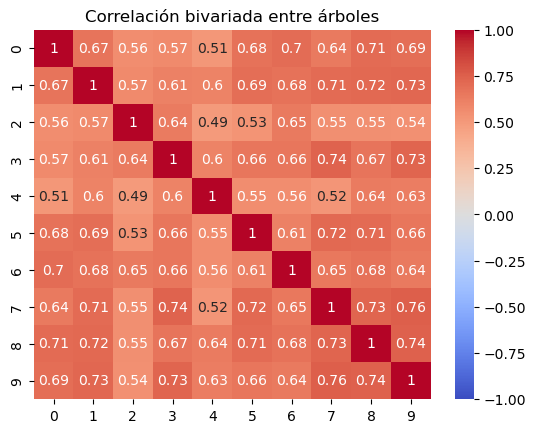

In [24]:
plot_cor(bag_clf_titanic, X_test_titanic)

# Bosques Aleatorios (Random Forest)

Para resolver el problema de correlación entre clasificadores, se incluye un mecanismo aleatorio de selección de atributos. Durante el entrenamiento, Random Forest selecciona un subconjunto de atributos de manera aleatoria, agregando diversidad en el proceso de crecimiento de los árboles.

<div align="center">
    <img src="img/rf.png" alt="" width="40%" align="center" />
</div>

# GridSearchCV with RandomForest

In [25]:
rf = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(estimator = rf, 
                           param_grid = {
                                'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 30, 50, 75, 100],
                                'n_estimators': [5, 10, 15, 20, 30, 50, 75, 100]}, 
                           cv=cv_splitter).fit(X_train_titanic,y_train_titanic)

print(grid_search.best_params_)

{'max_depth': 5, 'n_estimators': 30}


# Fit and predict with RandomForest

In [26]:
rf_titanic = RandomForestClassifier(**grid_search.best_params_)
rf_titanic.fit(X_train_titanic, y_train_titanic)
y_pred_titanic = rf_titanic.predict(X_test_titanic)
accuracy_score(y_test_titanic, y_pred_titanic)

0.7767441860465116

# Feature Importance with RandomForest

En un modelo de Random Forest, es posible identificar qué características (features) son más informativas.

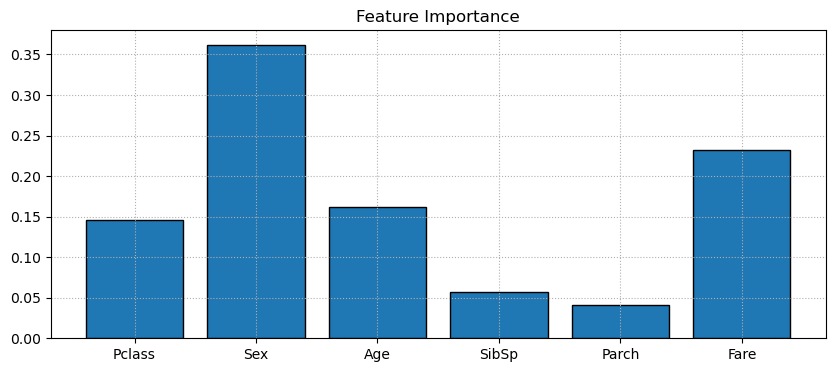

In [27]:
plot_feature_importance(X_train_titanic.columns, rf_titanic.feature_importances_)